# Parte A — Datos, partición y análisis descriptivo

Capa delgada sobre `src/` (núcleo §5.8): el notebook no calcula nada por su cuenta, solo llama funciones del
repositorio y muestra sus resultados. **Se edita este `.py`; el `.ipynb` lo genera `python run.py notebooks`.**

Todo se calcula **en memoria** a partir de `data/processed/loans_pd.parquet`: el notebook no escribe en
`data/processed/`, `models/`, `results/` ni `blog/` (esos archivos los consumen las demás partes). Para la
modificación en vivo, cambia `SET` (mismas claves que `--set`) y corre todo. Ejemplos:

- otra partición: `SET = {"particion.train_hasta": "2011-12-31", "particion.val_hasta": "2012-12-31"}`
- otro recorte: `SET = {"preprocesamiento.percentiles_recorte": [5.0, 95.0]}`
- otro umbral de monotonía: `SET = {"eda.umbral_monotonia": 0.8}`

Rehacer los datos desde el CSV crudo de Kaggle es otro comando: `python scripts/preparar_datos.py`.

In [1]:
CONFIG = "configs/datos.yaml"
SET = {}

In [2]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src.common.notebooks import config_notebook
from src.common.results import load_json

cfg = config_notebook(CONFIG, SET)

Configuración final resuelta:
crudo:
  csv: data/raw/credit-risk-dataset/loan/loan.csv
  diccionario: data/raw/credit-risk-dataset/LCDataDictionary.xlsx
  fecha_descarga: '2026-10-23'
  url: https://www.kaggle.com/datasets/ranadeep/credit-risk-dataset
features: configs/features.yaml
salida:
  carpeta: data/processed
  preprocesador: models/preprocesador_pd.json
particion:
  train_hasta: '2012-12-31'
  val_hasta: '2013-12-31'
  test_hasta: '2014-12-31'
eda:
  hipotesis: configs/hipotesis.yaml
  salida: results/data/eda
  umbral_monotonia: 0.9
preprocesamiento:
  percentiles_recorte:
  - 1.0
  - 99.0
base_seed: 0


## 1. Datos procesados (versionados en el repositorio)

In [3]:
resumen = load_json("data/processed/resumen_datos.json")
print(f"Registros crudos: {resumen['n_registros_crudo']:,} · variables: {resumen['n_variables_crudo']} · "
      f"periodo {resumen['periodo']['min']} a {resumen['periodo']['max']} · descarga {resumen['fecha_descarga']}")
pd.Series(resumen["conteo_por_loan_status"], name="créditos").to_frame()

Registros crudos: 887,379 · variables: 74 · periodo 2007-06 a 2015-12 · descarga 2026-10-23


,créditos
Current,601779
Fully Paid,207723
Charged Off,45248
Late (31-120 days),11591
Issued,8460
In Grace Period,6253
Late (16-30 days),2357
Does not meet the credit policy. Status:Fully Paid,1988
Default,1219
Does not meet the credit policy. Status:Charged Off,761


## 2. Partición, análisis descriptivo, hipótesis y datos después del preprocesamiento (en memoria)

In [4]:
from src.datos.experimento_eda import eda_en_memoria

eda = eda_en_memoria(cfg)
pd.DataFrame({"créditos": eda["particion"]["n_por_split"], "tasa de malos": eda["particion"]["tasa_malos_por_split"]})

,créditos,tasa de malos
train,90347,0.163027
val,73194,0.229500
test,74154,0.262171


In [5]:
pd.DataFrame([{"id": h["id"], "hipótesis": h["enunciado"], "lectura": h["veredicto_eda"]} for h in eda["hipotesis"]])

,id,hipótesis,lectura
0,H1,Los créditos a 60 meses son más riesgosos que ...,la apoya
1,H2,"A mayor razón deuda/ingreso (dti), mayor riesgo.",la apoya
2,H3,"A mayor ingreso anual, menor riesgo.",la apoya
3,H4,Más consultas de crédito en los últimos 6 mese...,la apoya
4,H5,"A mayor uso de los cupos rotativos, mayor riesgo.",la apoya
5,H6,Un historial crediticio más largo reduce el ri...,"la apoya, pero no es monótona"
6,H7,Quien arrienda es más riesgoso que quien paga ...,la apoya
7,H8,Los créditos para pequeña empresa son más ries...,la apoya
8,H9,Tener registros públicos negativos aumenta el ...,la apoya
9,H10,"A mayor monto solicitado, mayor riesgo.","la apoya, pero no es monótona"


In [6]:
pd.DataFrame(eda["post"]["psi_vs_train"]).sort_values("test", ascending=False).round(3)

,val,test
purpose,0.193,0.270
pub_rec,0.107,0.269
antiguedad_credito_anios,0.061,0.113
total_acc,0.066,0.112
dti,0.078,0.112
open_acc,0.081,0.104
loan_amnt,0.121,0.089
term,0.017,0.064
revol_util,0.077,0.062
emp_length,0.054,0.059


## 3. Figuras (las mismas del blog, dibujadas con esta configuración en una carpeta temporal)

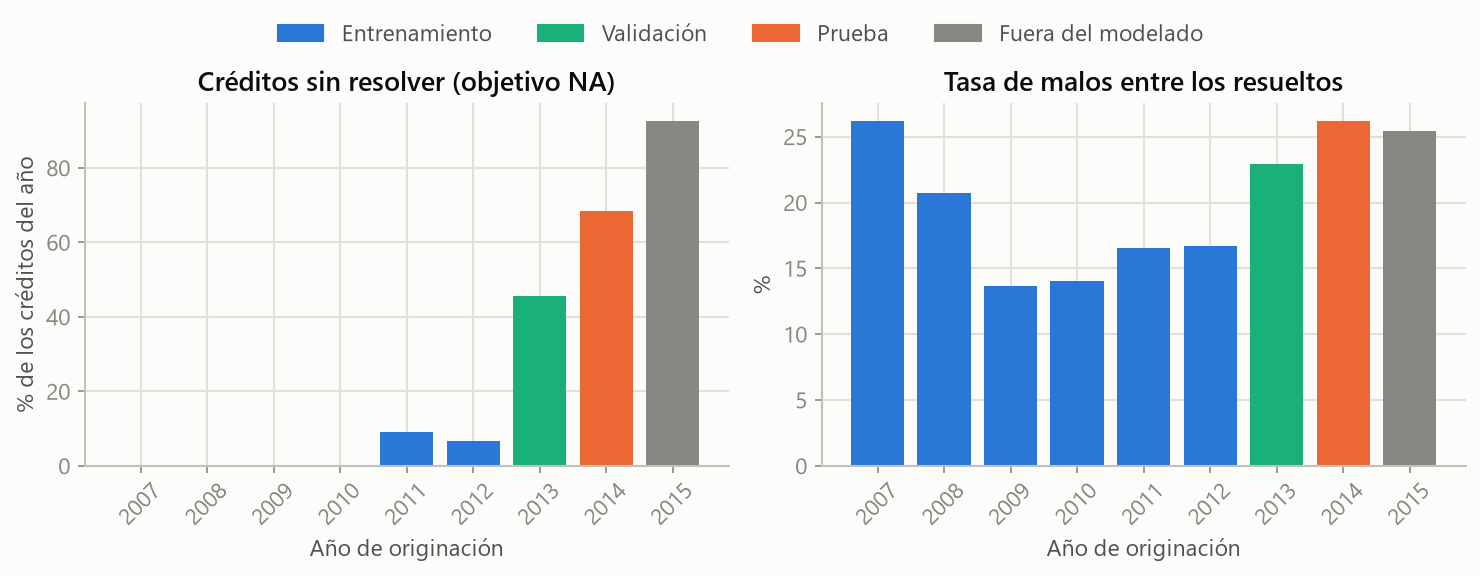

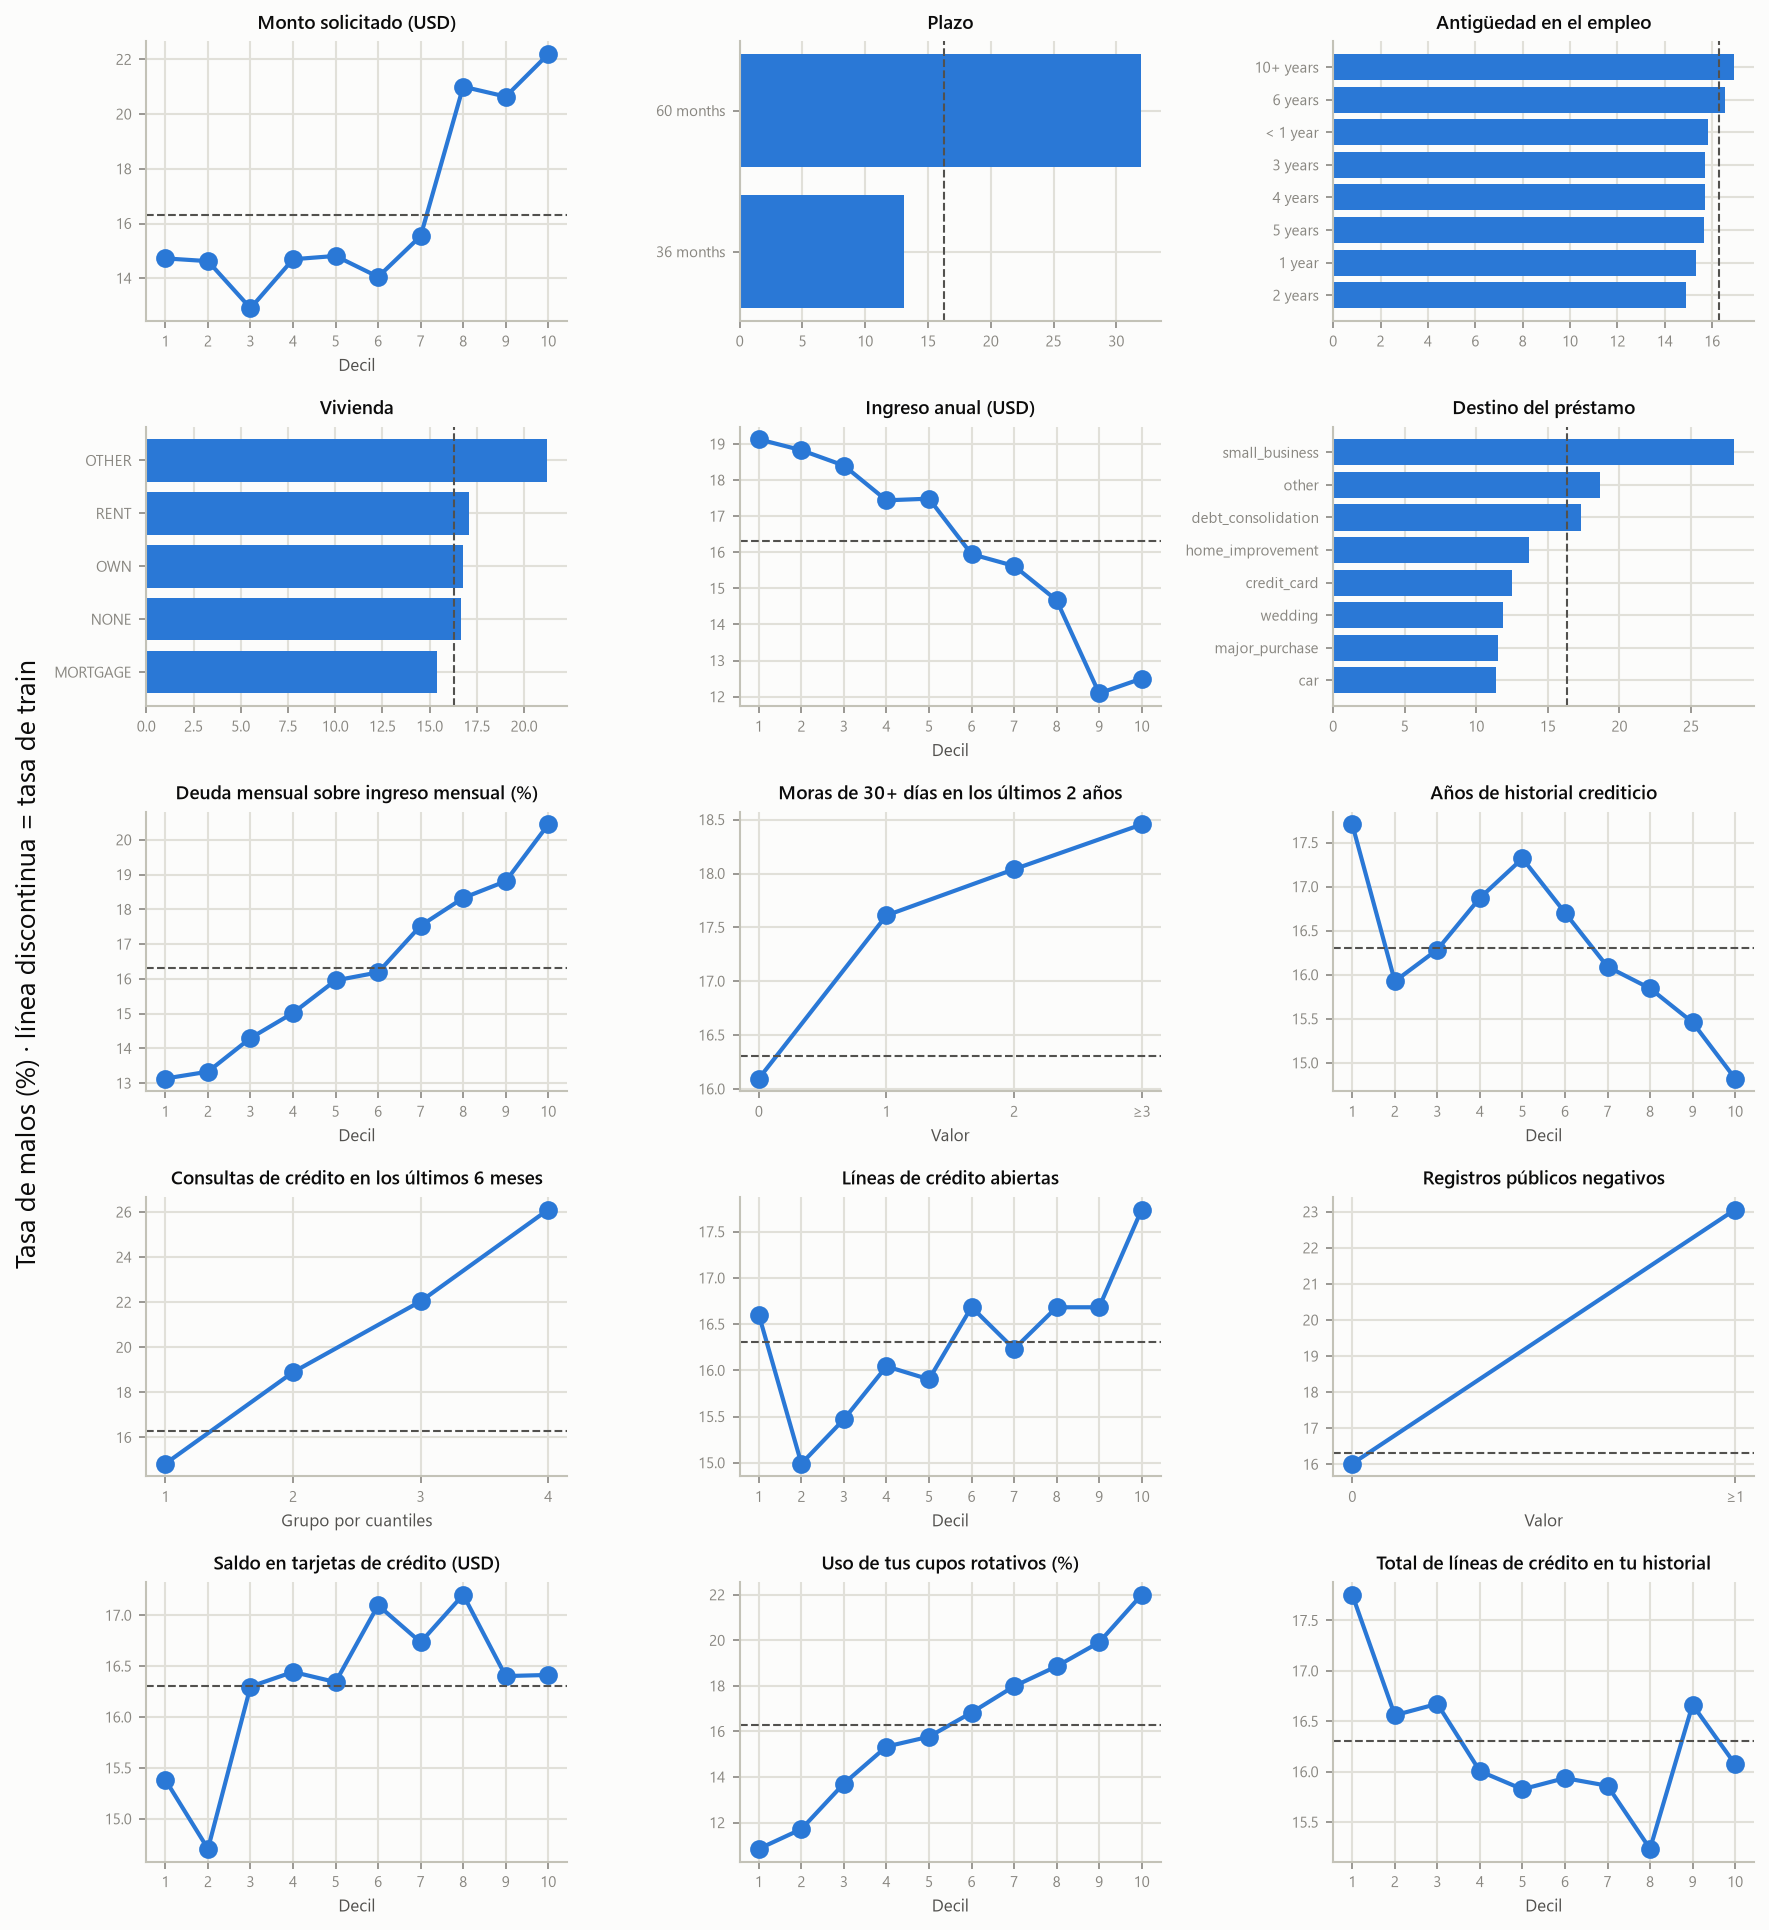

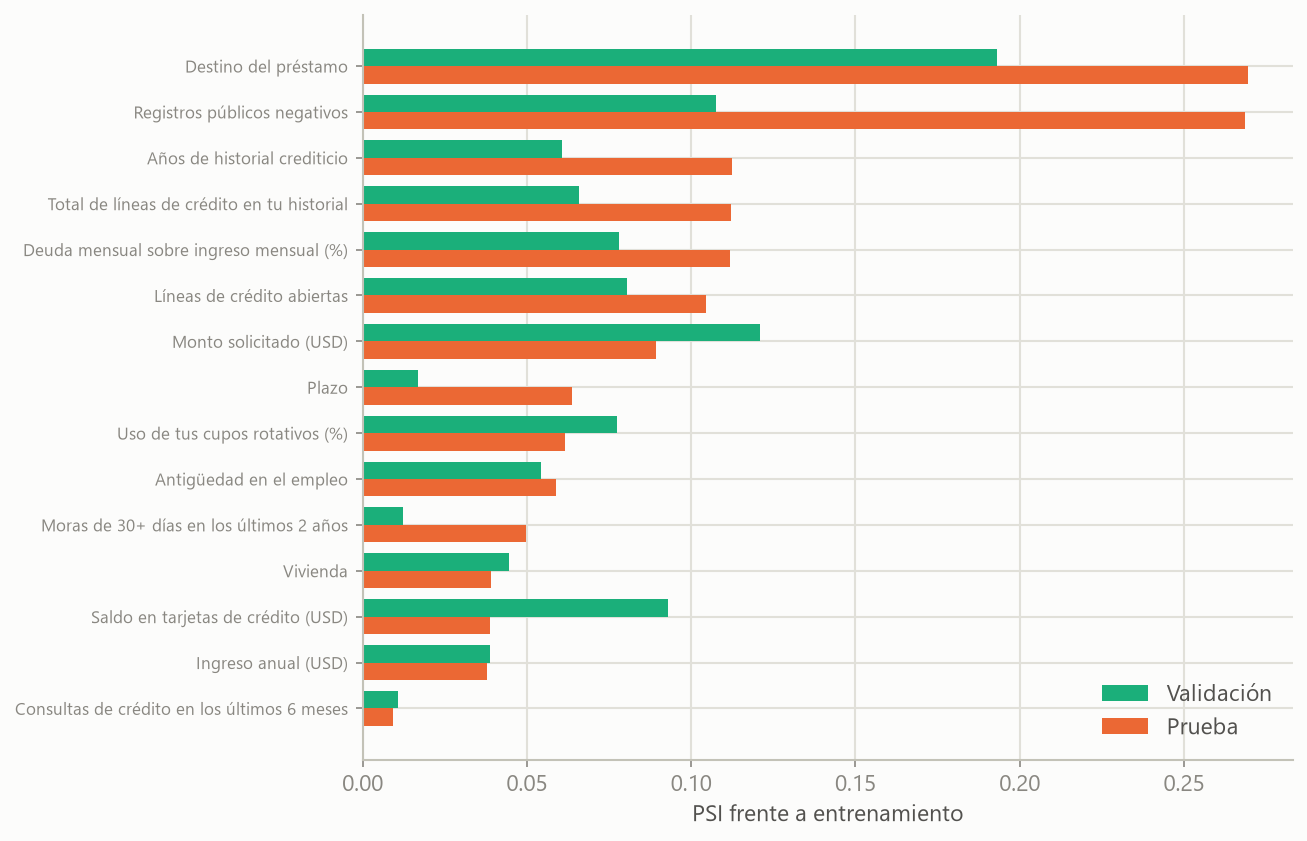

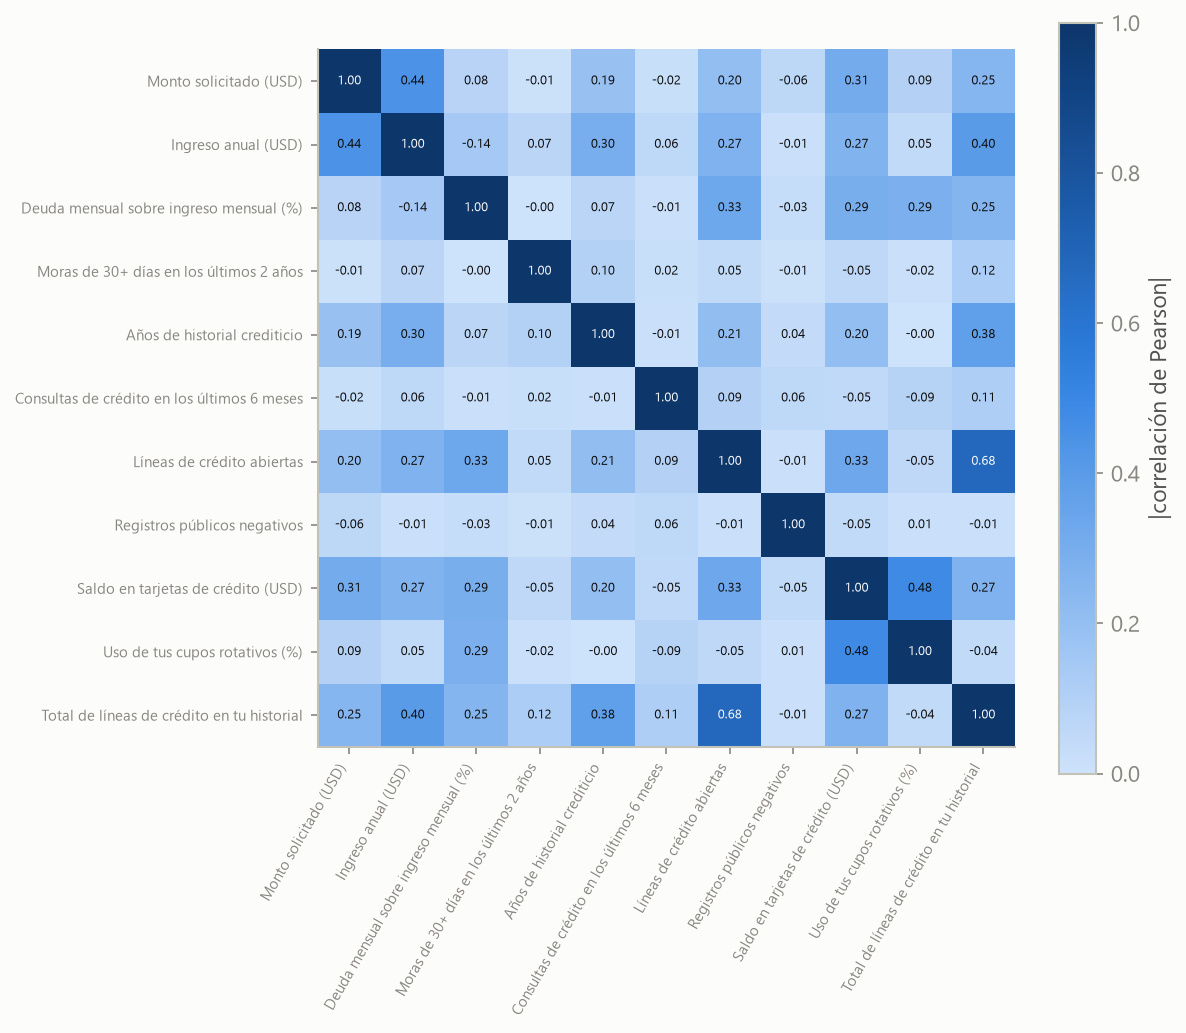

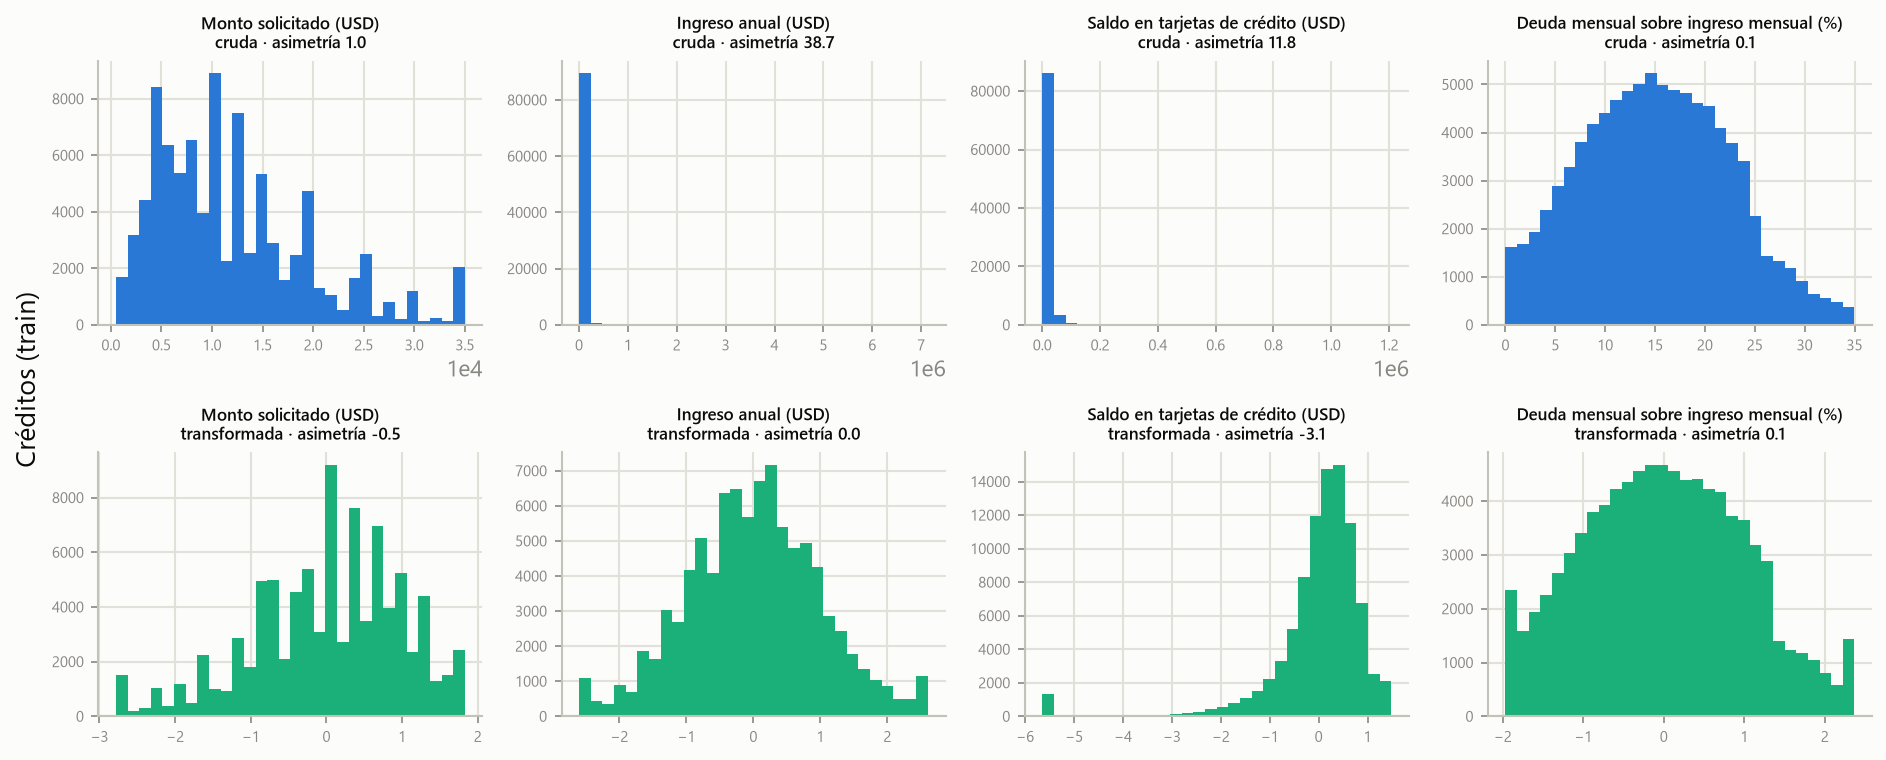

In [7]:
from src.viz.figs_datos import generar

for ruta in generar(destino=Path(tempfile.mkdtemp()), datos=eda):
    display(Image(filename=str(ruta)))